# Customer Churn Analysis & Exploration
**CodeNova AI/ML Internship – Batch 02 | Task 1**

**Objective:** Explore the public *Telco Customer Churn* dataset (IBM sample data) to find the main drivers of customer attrition and turn them into retention actions.

**Sections:** 1. Setup & load · 2. Statistical profiling · 3. Churn distribution · 4. Contract analysis · 5. Tenure & charges · 6. Other drivers · 7. Correlation heatmap · 8. Summary of insights

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os, warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
os.makedirs('images', exist_ok=True)
PALETTE = {'No': '#4C78A8', 'Yes': '#E45756'}

def save(name):
    plt.savefig(f'images/{name}.png', dpi=300, bbox_inches='tight')

df = pd.read_csv('data/Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Statistical profiling

In [2]:
print('Shape:', df.shape)
df.info()

Shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   s

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [4]:
# TotalCharges is stored as text -> convert to numeric (blank strings become NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

missing = df.isna().sum()
print('Missing values per column (only columns with missing):')
print(missing[missing > 0])
print('\nTenure of rows with missing TotalCharges:', df.loc[df['TotalCharges'].isna(), 'tenure'].unique())
print('Duplicate customerIDs:', df['customerID'].duplicated().sum())

Missing values per column (only columns with missing):
TotalCharges    11
dtype: int64

Tenure of rows with missing TotalCharges: [0]
Duplicate customerIDs: 0


**Data-quality notes**
- 7,043 customers, 21 columns, no duplicate customer IDs.
- `TotalCharges` had 11 blank values. All of them belong to customers with `tenure = 0` (brand-new, not yet billed), so the correct fix is to set them to **0** rather than dropping or averaging.

In [5]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['ChurnFlag'] = (df['Churn'] == 'Yes').astype(int)   # 1 = churned
print('Missing values left:', df.isna().sum().sum())

Missing values left: 0


## 2. Churn distribution

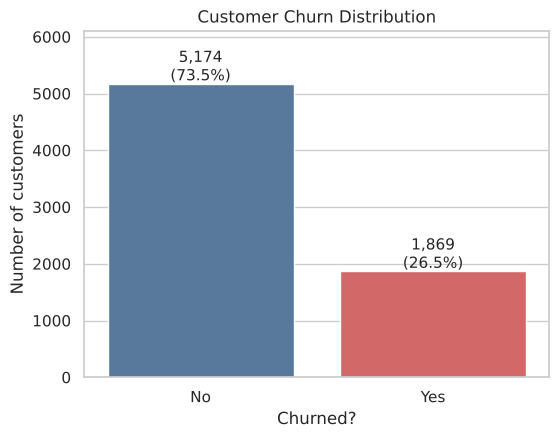

In [6]:
counts = df['Churn'].value_counts()
pct = df['Churn'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.countplot(data=df, x='Churn', order=['No', 'Yes'], palette=PALETTE, ax=ax)
for i, lab in enumerate(['No', 'Yes']):
    ax.text(i, counts[lab] + 60, f'{counts[lab]:,}\n({pct[lab]:.1f}%)', ha='center', fontsize=11)
ax.set_title('Customer Churn Distribution')
ax.set_xlabel('Churned?')
ax.set_ylabel('Number of customers')
ax.set_ylim(0, counts.max() * 1.18)
save('01_churn_distribution'); plt.show()

**Business takeaway:** about **26.5%** of customers (1,869 of 7,043) churned, so roughly 1 in 4 customers leaves. The classes are imbalanced (≈73/27), which matters if this dataset is later used to train a churn model: plain accuracy would be misleading, and precision/recall should be tracked.

## 3. Contract type vs churn

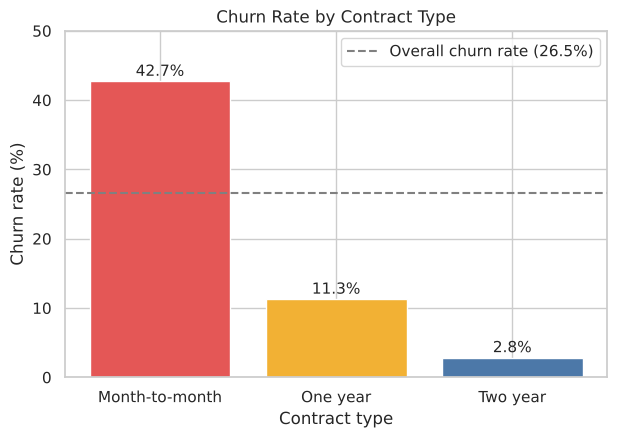

                count   sum   mean
Contract                          
Month-to-month   3875  1655  0.427
One year         1473   166  0.113
Two year         1695    48  0.028


In [7]:
ct = df.groupby('Contract')['ChurnFlag'].mean().mul(100).reindex(['Month-to-month', 'One year', 'Two year'])

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(ct.index, ct.values, color=['#E45756', '#F2B134', '#4C78A8'])
for b, v in zip(bars, ct.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f'{v:.1f}%', ha='center', fontsize=11)
ax.axhline(df['ChurnFlag'].mean() * 100, ls='--', color='grey', label='Overall churn rate (26.5%)')
ax.set_title('Churn Rate by Contract Type')
ax.set_xlabel('Contract type')
ax.set_ylabel('Churn rate (%)')
ax.set_ylim(0, 50)
ax.legend()
save('02_churn_by_contract'); plt.show()
print(df.groupby('Contract')['ChurnFlag'].agg(['count', 'sum', 'mean']).round(3))

**Business takeaway:** contract type is the strongest single driver. **Month-to-month customers churn at 42.7%**, versus **11.3%** for one-year and just **2.8%** for two-year contracts, a ~15x gap. Retention action: offer discounts or perks to move month-to-month customers onto 1-2 year plans, ideally after their first few months.

## 4. Tenure and monthly charges vs churn

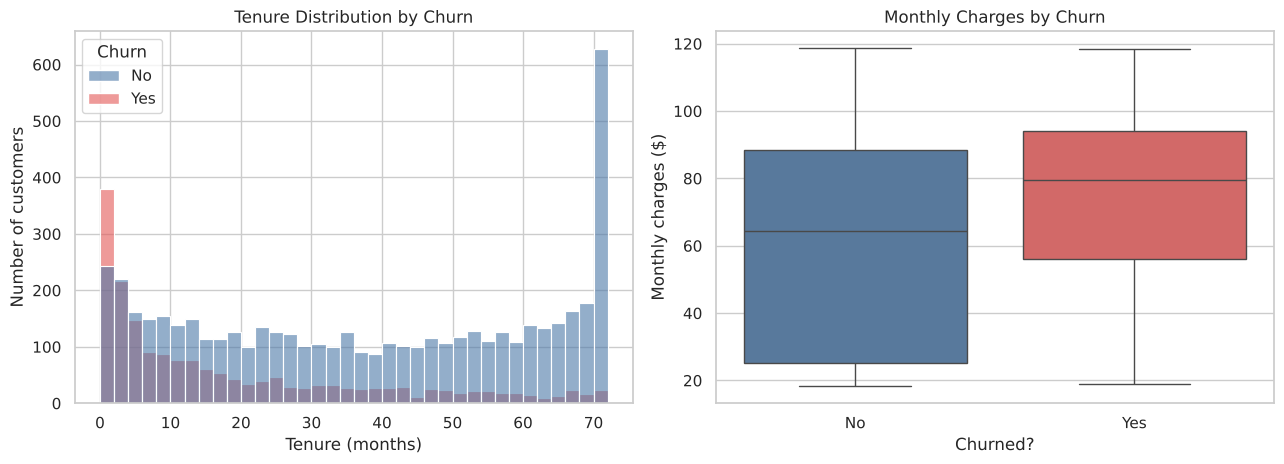

      tenure        MonthlyCharges       
        mean median           mean median
Churn                                    
No      37.6   38.0           61.3   64.4
Yes     18.0   10.0           74.4   79.6


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.histplot(data=df, x='tenure', hue='Churn', bins=36, multiple='layer', palette=PALETTE, alpha=0.6, ax=axes[0])
axes[0].set_title('Tenure Distribution by Churn')
axes[0].set_xlabel('Tenure (months)')
axes[0].set_ylabel('Number of customers')

sns.boxplot(data=df, x='Churn', y='MonthlyCharges', order=['No', 'Yes'], palette=PALETTE, ax=axes[1])
axes[1].set_title('Monthly Charges by Churn')
axes[1].set_xlabel('Churned?')
axes[1].set_ylabel('Monthly charges ($)')
plt.tight_layout()
save('03_tenure_monthly_charges'); plt.show()

print(df.groupby('Churn')[['tenure', 'MonthlyCharges']].agg(['mean', 'median']).round(1))

**Business takeaway:** churned customers are **new and pay more**. Median tenure is **10 months** for churners vs **38** for retained customers, and median monthly charge is **$79.65** vs **$64.43**. The first year is the danger zone, so invest in onboarding and early-life engagement, and review whether high-priced plans deliver enough perceived value.

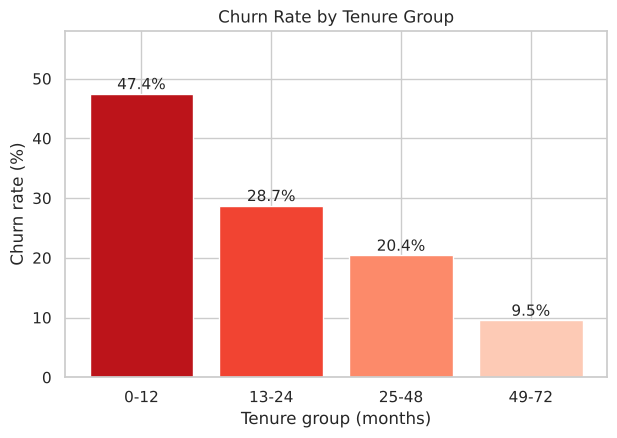

In [9]:
df['TenureGroup'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 72], labels=['0-12', '13-24', '25-48', '49-72'])
tg = df.groupby('TenureGroup', observed=True)['ChurnFlag'].mean().mul(100)

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(tg.index.astype(str), tg.values, color=sns.color_palette('Reds_r', 4))
for b, v in zip(bars, tg.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f'{v:.1f}%', ha='center', fontsize=11)
ax.set_title('Churn Rate by Tenure Group')
ax.set_xlabel('Tenure group (months)')
ax.set_ylabel('Churn rate (%)')
ax.set_ylim(0, 58)
save('04_churn_by_tenure_group'); plt.show()

**Business takeaway:** churn falls steadily with tenure, from **47.4%** in the first 12 months to **9.5%** after 4 years. Customers who survive year one become much more loyal, so reducing early churn has the biggest payoff.

## 5. Service and customer-profile drivers

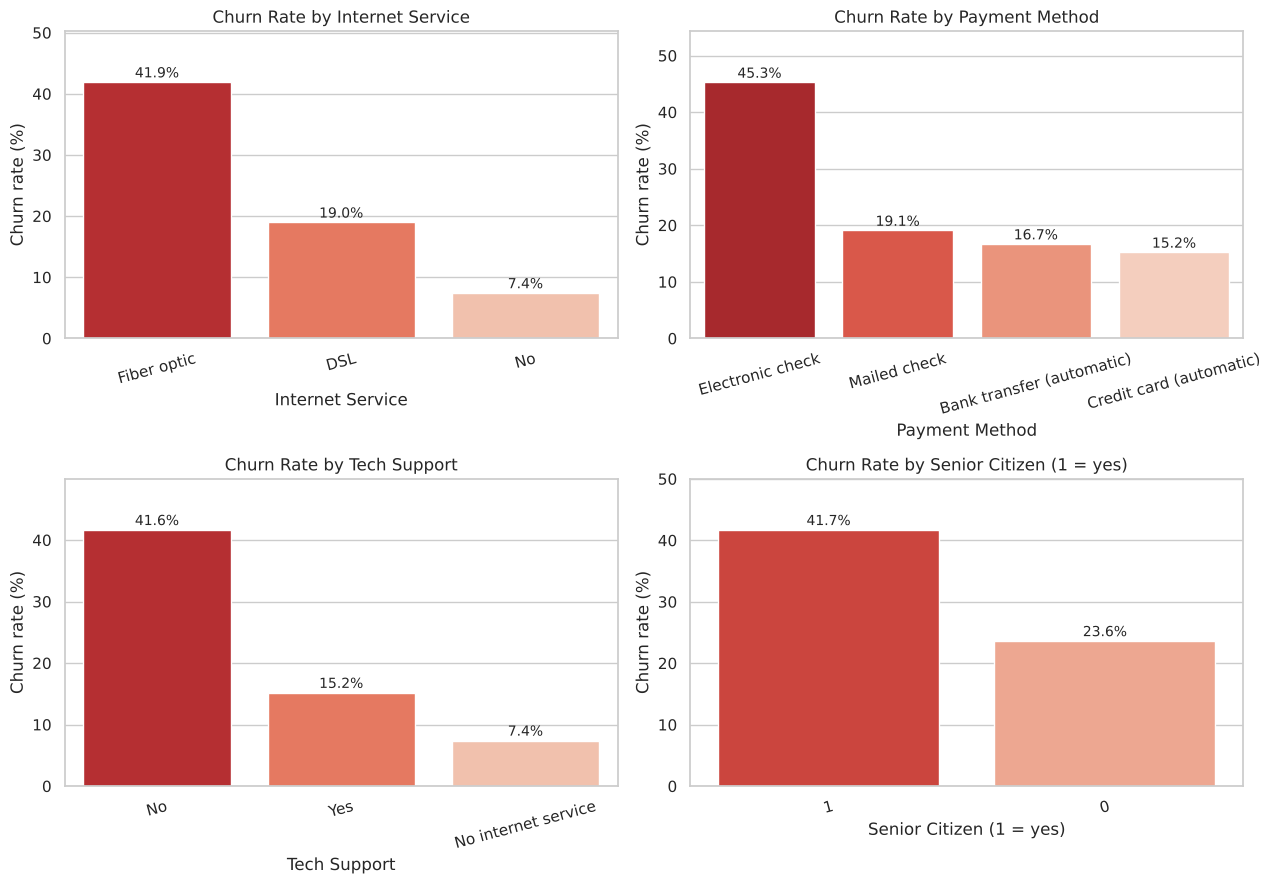

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
cols = [('InternetService', 'Internet Service'), ('PaymentMethod', 'Payment Method'),
        ('TechSupport', 'Tech Support'), ('SeniorCitizen', 'Senior Citizen (1 = yes)')]
for ax, (col, title) in zip(axes.ravel(), cols):
    rate = df.groupby(col)['ChurnFlag'].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, palette='Reds_r', ax=ax)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.8, f'{v:.1f}%', ha='center', fontsize=10)
    ax.set_title(f'Churn Rate by {title}')
    ax.set_xlabel(title)
    ax.set_ylabel('Churn rate (%)')
    ax.set_ylim(0, rate.max() * 1.2)
    ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
save('05_other_drivers'); plt.show()

**Business takeaways**
- **Fiber optic** customers churn at **41.9%** vs 19.0% for DSL. Combined with their higher bills, this suggests a price/quality or competition problem in the fiber segment worth investigating.
- **Electronic check** payers churn at **45.3%**, versus roughly 15-19% for the other payment methods. Encouraging automatic payments (bank transfer/credit card) may help.
- Customers **without tech support** churn at **41.6%** vs **15.2%** with it (online security shows the same pattern: 41.8% vs 14.6%). Bundling support services could reduce churn.
- **Senior citizens** churn at **41.7%** vs 23.6% for others, so a targeted senior-friendly offer is worth testing.

*Note: these are associations, not proven causes.*

## 6. Correlation heatmap

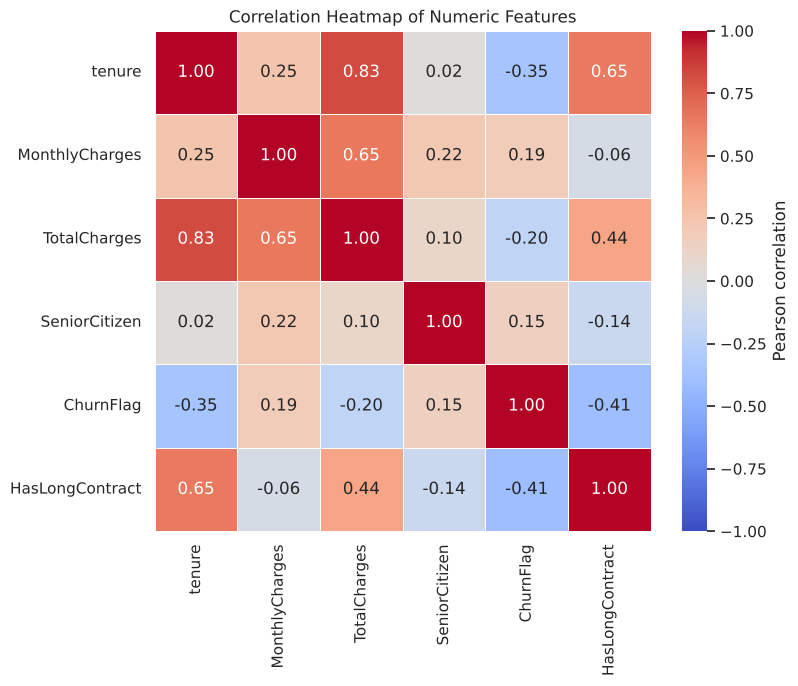

HasLongContract   -0.405103
tenure            -0.352229
TotalCharges      -0.198324
SeniorCitizen      0.150889
MonthlyCharges     0.193356
Name: ChurnFlag, dtype: float64

In [11]:
num = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'ChurnFlag']].copy()
num['HasLongContract'] = (df['Contract'] != 'Month-to-month').astype(int)
corr = num.corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={'label': 'Pearson correlation'}, ax=ax)
ax.set_title('Correlation Heatmap of Numeric Features')
save('06_correlation_heatmap'); plt.show()
corr['ChurnFlag'].drop('ChurnFlag').sort_values()

**Business takeaway:** having a 1-2 year contract has the strongest negative correlation with churn (**-0.41**), followed by `tenure` (**-0.35**). `MonthlyCharges` (+0.19) and `SeniorCitizen` (+0.15) are positive. `TotalCharges` (-0.20) is correlated mainly because it grows with tenure, so it adds little on its own. Even the strongest correlation is only about 0.4 in absolute value, so churn is driven by a *combination* of factors rather than one variable.

## 7. Summary of key findings
| Rank | Driver | Evidence |
|---|---|---|
| 1 | Month-to-month contract | 42.7% churn vs 2.8% (two-year) |
| 2 | Short tenure | 47.4% churn in first 12 months; median tenure 10 vs 38 months |
| 3 | Fiber optic internet | 41.9% churn vs 19.0% DSL |
| 4 | Electronic check payment | 45.3% churn |
| 5 | No tech support / online security | ~42% churn vs ~15% with them |
| 6 | Higher monthly charges, senior citizens | Median $79.65 vs $64.43; 41.7% vs 23.6% |

**Recommended actions:** (1) push new customers toward longer contracts, (2) strengthen first-year onboarding, (3) bundle security/tech support, (4) promote automatic payment, (5) investigate fiber-optic service quality and pricing.